# Detección de tumores cerebrales en resonancias magnéticas con Deep Learning

Los tumores cerebrales son una de las enfermedades neurológicas más graves: su diagnóstico temprano influye directamente en las opciones de tratamiento y en el pronóstico del paciente. La resonancia magnética (MRI) es la técnica de imagen más utilizada para detectarlos, ya que ofrece un alto contraste entre tejidos blandos sin emplear radiación ionizante.

Sin embargo, la interpretación de estas imágenes depende de especialistas en la materia; es un proceso que consume tiempo y puede verse afectado por la fatiga o por la variabilidad entre medicos. Además, en muchas regiones el número de especialistas es limitado frente a la demanda de estudios.

En este proyecto se plantea un problema de **clasificación binaria de imágenes**: dada una resonancia magnética cerebral, determinar si presenta un tumor o no. Para resolverlo se emplean **redes neuronales convolucionales (CNN)** implementadas con Keras y TensorFlow, comparando un modelo diseñado desde cero con un modelo basado en *transfer learning*.

El objetivo no es sustituir el diagnóstico médico, sino explorar cómo un modelo de este tipo podría funcionar como **herramienta de apoyo**: priorizar estudios sospechosos, servir como segunda opinión o agilizar la revisión de grandes volúmenes de imágenes. Por ello, además de la exactitud general, se da especial importancia al *recall* de la clase tumor, ya que un tumor no detectado es el error más costoso en este contexto.

### Descripción del dataset

Se utilizará el dataset público de Kaggle *"Brian Tumor Dataset"* (autor: Preet Viradiya), que contiene 4,600 imágenes de resonancia magnética (MRI) cerebral divididas en dos clases: **tumor** (2,513 imágenes) y **normal/sano** (2,087 imágenes). El objetivo es entrenar un clasificador binario capaz de distinguir entre ambos casos.

Las imágenes tienen tamaños y formatos heterogéneos (JPEG, PNG y TIFF; en RGB y escala de grises), por lo que fue necesario un preprocesamiento para uniformizarlas.

**Fuente:** [Brian Tumor Dataset – Kaggle](https://www.kaggle.com/datasets/preetviradiya/brian-tumor-dataset)

In [5]:
from google.colab import drive
import os

# Montar Google Drive
drive.mount('/content/drive')

# Definir la ruta hacia tu dataset en Google Drive
# Nota: Ajusta 'Brain Tumor Data Set' si tu carpeta tiene un nombre diferente o está dentro de otra subcarpeta
DATA_DIR = "/content/drive/MyDrive/Brain Tumor Data Set"

# Verificar que la ruta exista
if os.path.exists(DATA_DIR):
    print("¡Drive montado y carpeta del dataset localizada con éxito!")
    print("Contenido de la carpeta:", os.listdir(DATA_DIR))
else:
    print(f"Error: No se encontró la carpeta en {DATA_DIR}. Por favor verifica el nombre exacto en tu Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
¡Drive montado y carpeta del dataset localizada con éxito!
Contenido de la carpeta: ['Healthy', 'Brain Tumor']


In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = "Brain Tumor Data Set"

TensorFlow: 2.21.0


### Exploración de los datos

Se revisa la estructura de carpetas, el archivo `metadata.csv` (nombre, clase, formato, modo de color y dimensiones de cada imagen) y algunos ejemplos de cada clase.

In [7]:
for root, dirs, files in os.walk(DATA_DIR):
    print(root, "->", len(files), "archivos")

In [8]:
meta = pd.read_csv("metadata.csv")
meta_rgb = pd.read_csv("metadata_rgb_only.csv")

print(meta.shape, meta_rgb.shape)
display(meta.head())
print(meta.dtypes)

(4600, 6) (4461, 6)


,Unnamed: 0,image,class,format,mode,shape
0,0,Cancer (1).jpg,tumor,JPEG,RGB,"(512, 512, 3)"
1,1,Cancer (1).png,tumor,PNG,L,"(300, 240)"
2,2,Cancer (1).tif,tumor,TIFF,RGB,"(256, 256, 3)"
3,3,Cancer (10).jpg,tumor,JPEG,RGB,"(512, 512, 3)"
4,4,Cancer (10).tif,tumor,TIFF,RGB,"(256, 256, 3)"


Unnamed: 0     int64
image         object
class         object
format        object
mode          object
shape         object
dtype: object


class
tumor     2513
normal    2087
Name: count, dtype: int64
format
JPEG    4496
TIFF      86
PNG       18
Name: count, dtype: int64
mode
RGB     4461
L        132
RGBA       5
P          2
Name: count, dtype: int64


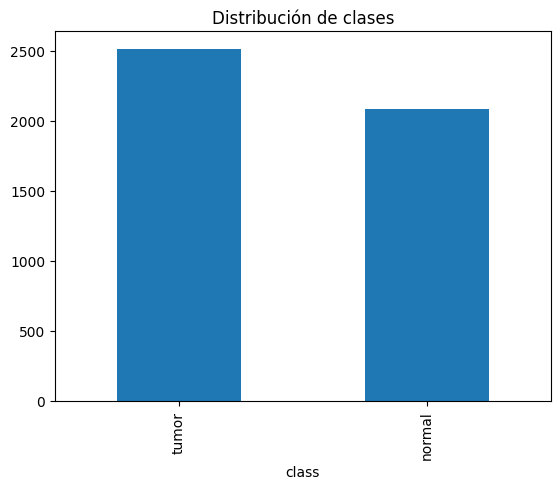

In [9]:
print(meta["class"].value_counts())
print(meta["format"].value_counts())
print(meta["mode"].value_counts())   # RGB vs. escala de grises

meta["class"].value_counts().plot(kind="bar", title="Distribución de clases")
plt.show()

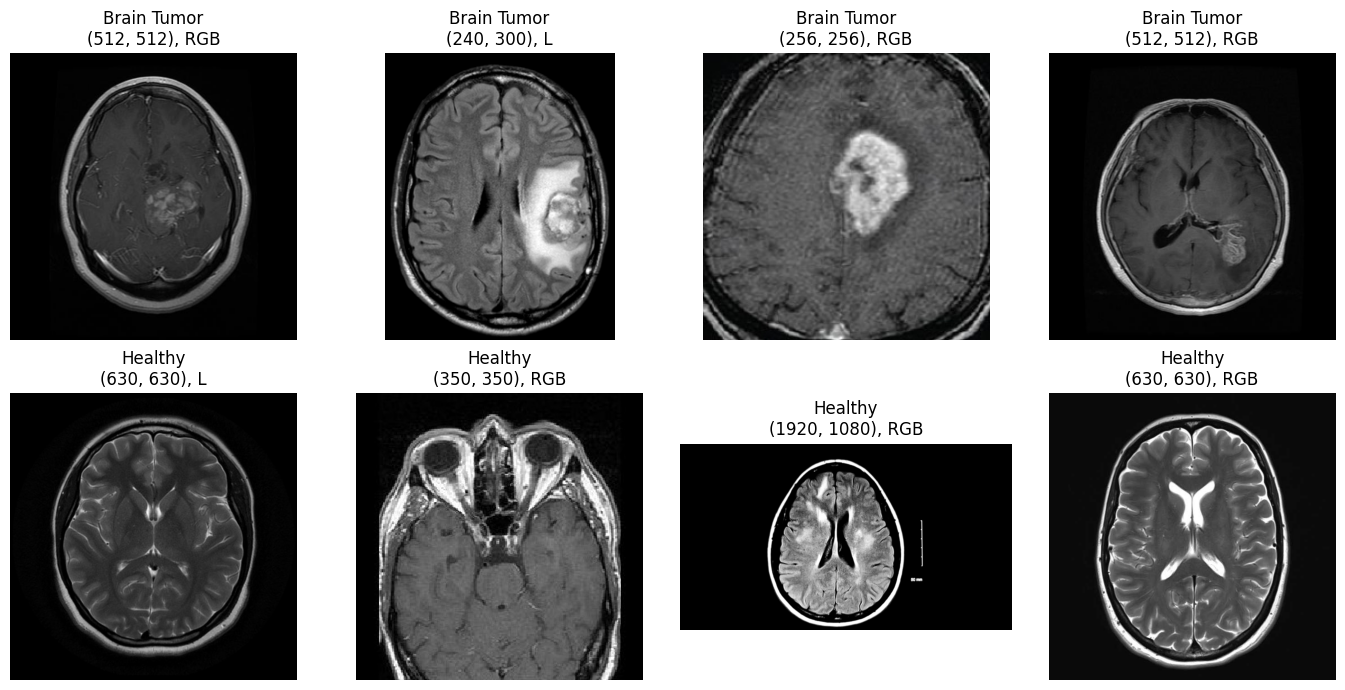

In [10]:
from PIL import Image
import os

# Usar la ruta correcta de Google Drive que definimos al inicio
DATA_DIR_DRIVE = "/content/drive/MyDrive/Brain Tumor Data Set"

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, clase in enumerate(["Brain Tumor", "Healthy"]):
    carpeta = os.path.join(DATA_DIR_DRIVE, clase)
    archivos = sorted(os.listdir(carpeta))[:4]
    for col, f in enumerate(archivos):
        img = Image.open(os.path.join(carpeta, f))
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(f"{clase}\n{img.size}, {img.mode}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

### Análisis y preprocesamiento

**Balance de clases:** el dataset está razonablemente balanceado (54.6% tumor y 45.4% normal), por lo que no se aplicaron pesos por clase. Aun así, además de la exactitud se reportan *precision*, *recall* y F1 por clase.

**Formatos y modos de color:** la tabla cruzada de la siguiente celda muestra que **los 86 archivos TIFF pertenecen a la clase tumor**, y que los modos RGBA y P (paleta) solo aparecen en imágenes normales. Esto representa un riesgo de "atajo": el modelo podría aprender a reconocer el formato de origen en lugar del tumor. Para mitigarlo, todas las imágenes se decodifican y se convierten al mismo formato antes de entrar al modelo.

**Preprocesamiento aplicado:**

1. Conversión de todas las imágenes a **RGB** (3 canales), incluidas las de escala de grises (`L`), RGBA y paleta (`P`). Por eso se usa `metadata.csv` completo y no `metadata_rgb_only.csv`, que descartaría 139 imágenes.
2. Redimensionamiento a **224 × 224** píxeles, ya que los tamaños originales van de 240×300 a 1920×1080.
3. La **normalización** de píxeles no se hace aquí, sino dentro de cada modelo (capa `Rescaling` o la normalización interna de EfficientNet). Así, el archivo `.keras` incluye su propio preprocesamiento.

**Separación de datos:** se hizo una división **estratificada** con semilla fija (`random_state=42`) en 70% entrenamiento (3,220 imágenes), 15% validación (690) y 15% prueba (690), conservando la misma proporción de clases en los tres conjuntos. El conjunto de validación se usa para comparar modelos y ajustar hiperparámetros; el de prueba se reserva para la evaluación final.


In [11]:
CLASS_TO_FOLDER = {"tumor": "Brain Tumor", "normal": "Healthy"}
CLASS_TO_LABEL  = {"normal": 0, "tumor": 1}

df = meta.drop(columns=["Unnamed: 0"]).copy()
df["path"] = df.apply(
    lambda r: os.path.join(DATA_DIR, CLASS_TO_FOLDER[r["class"]], r["image"]), axis=1
)
df["label"] = df["class"].map(CLASS_TO_LABEL)

faltan = df[~df["path"].apply(os.path.exists)]
print("Archivos faltantes:", len(faltan))

print(pd.crosstab(df["class"], df["format"]))
print(pd.crosstab(df["class"], df["mode"]))

Archivos faltantes: 4600
format  JPEG  PNG  TIFF
class                  
normal  2078    9     0
tumor   2418    9    86
mode     L  P   RGB  RGBA
class                    
normal  40  2  2040     5
tumor   92  0  2421     0


In [12]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

for nombre, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(nombre, len(d), d["class"].value_counts(normalize=True).round(3).to_dict())

train 3220 {'tumor': 0.546, 'normal': 0.454}
val 690 {'tumor': 0.546, 'normal': 0.454}
test 690 {'tumor': 0.546, 'normal': 0.454}


In [13]:
from PIL import Image
from tqdm.auto import tqdm
import os

IMG_SIZE = 224

DATA_DIR_DRIVE = "/content/drive/MyDrive/Brain Tumor Data Set"

def cargar_imagenes(dataframe):
    X = np.zeros((len(dataframe), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for i, (idx, fila) in enumerate(tqdm(dataframe.iterrows(), total=len(dataframe), leave=False)):
        # Obtenemos el nombre de la carpeta de clase de manera segura mediante el diccionario
        clase_carpeta = CLASS_TO_FOLDER[fila["class"]]
        ruta_correcta = os.path.join(DATA_DIR_DRIVE, clase_carpeta, fila["image"])
        img = Image.open(ruta_correcta).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        X[i] = np.asarray(img)
    y = dataframe["label"].to_numpy().astype("float32")
    return X, y

X_train, y_train = cargar_imagenes(train_df)
X_val,   y_val   = cargar_imagenes(val_df)
X_test,  y_test  = cargar_imagenes(test_df)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape,   y_val.shape)
print("Test: ", X_test.shape,  y_test.shape)
print("RAM aprox (MB):", (X_train.nbytes + X_val.nbytes + X_test.nbytes) / 1e6)

  0%|          | 0/3220 [00:00<?, ?it/s]

  0%|          | 0/690 [00:00<?, ?it/s]

  0%|          | 0/690 [00:00<?, ?it/s]

Train: (3220, 224, 224, 3) (3220,)
Val:   (690, 224, 224, 3) (690,)
Test:  (690, 224, 224, 3) (690,)
RAM aprox (MB): 692.4288


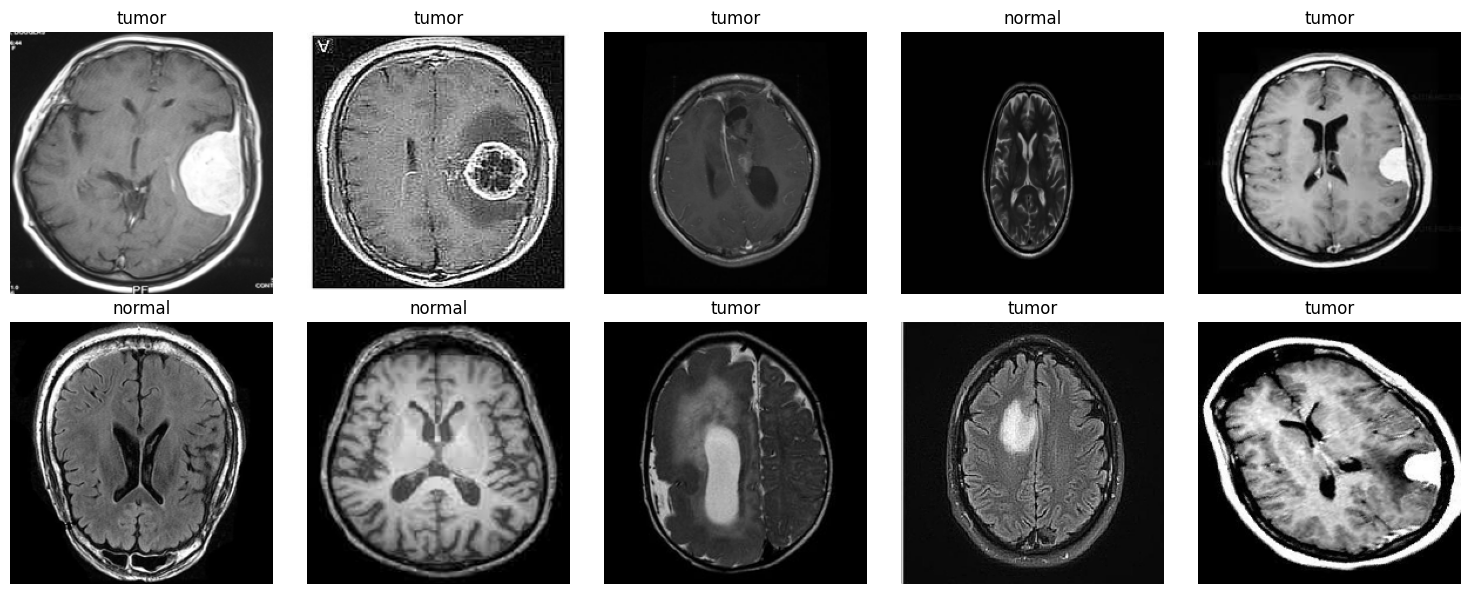

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, i in zip(axes.ravel(), np.random.choice(len(X_train), 10, replace=False)):
    ax.imshow(X_train[i])
    ax.set_title("tumor" if y_train[i] == 1 else "normal")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Desarrollo del modelo

Como primera aproximación se diseñó una **red neuronal convolucional (CNN) desde cero**, sin técnicas de regularización, para establecer una línea base contra la cual comparar las mejoras posteriores.

Se eligió una CNN porque las capas convolucionales aprovechan la estructura espacial de las imágenes: cada filtro aprende patrones locales y comparte sus pesos en toda la imagen. Esto requiere muchos menos parámetros que una red densa y permite detectar un tumor sin importar en qué zona del cerebro aparezca.

La arquitectura consta de:

| Bloque | Capas | Salida |
|---|---|---|
| Entrada | `Input` + `Rescaling(1/255)` | 224 × 224 × 3 |
| Bloque 1 | `Conv2D(32, 3×3, ReLU)` + `MaxPooling2D` | 112 × 112 × 32 |
| Bloque 2 | `Conv2D(64, 3×3, ReLU)` + `MaxPooling2D` | 56 × 56 × 64 |
| Bloque 3 | `Conv2D(128, 3×3, ReLU)` + `MaxPooling2D` | 28 × 28 × 128 |
| Bloque 4 | `Conv2D(128, 3×3, ReLU)` + `MaxPooling2D` | 14 × 14 × 128 |
| Clasificador | `Flatten` + `Dense(128, ReLU)` + `Dense(1, Sigmoid)` | 1 |

- **Rescaling:** normaliza los píxeles al rango [0, 1] dentro del propio modelo, de modo que el archivo `.keras` incluye el preprocesamiento y puede recibir imágenes sin normalizar.
- **Bloques convolucionales:** el número de filtros aumenta (32 → 64 → 128) conforme la resolución disminuye, de forma que las primeras capas capturan rasgos simples y las más profundas combinan esos rasgos en patrones más complejos, como la forma y textura de una masa tumoral.
- **MaxPooling:** reduce a la mitad la resolución en cada bloque, lo que disminuye el costo computacional y da cierta invariancia a pequeñas traslaciones.
- **Salida sigmoide:** al ser un problema de clasificación binaria, una sola neurona devuelve la probabilidad de que la imagen contenga un tumor (clase 1).

El modelo tiene aproximadamente **3.45 millones de parámetros**, de los cuales cerca del 93% pertenecen a la capa densa posterior al `Flatten`. Esto lo hace propenso al sobreajuste, aspecto que se aborda en la sección de ajuste.



In [15]:
BATCH_SIZE = 32

def hacer_dataset(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = hacer_dataset(X_train, y_train, shuffle=True)
val_ds   = hacer_dataset(X_val, y_val)
test_ds  = hacer_dataset(X_test, y_test)   # no se usa hasta la sección Resultados

In [16]:
from tensorflow.keras import layers, models

def crear_modelo_base():
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Rescaling(1./255),

        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ], name="cnn_base")
    return model

modelo_base = crear_modelo_base()
modelo_base.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,452,353 (13.17 MB)

 Trainable params: 3,452,353 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

### Entrenamiento

El modelo se compiló con los siguientes parámetros:

- **Función de pérdida:** `binary_crossentropy`, estándar para clasificación binaria con salida sigmoide.
- **Optimizador:** Adam con tasa de aprendizaje de 0.001, que ajusta la tasa por parámetro y suele converger rápido sin mucho ajuste manual.
- **Métricas:** además de *accuracy*, se monitorean *precision*, *recall* y *AUC*. En un contexto médico el *recall* de la clase tumor es especialmente importante, ya que un falso negativo (clasificar como sano a un paciente con tumor) es el error más costoso.
- **Tamaño de lote:** 32 imágenes.
- **Épocas:** máximo 25, con **Early Stopping** sobre la pérdida de validación (paciencia de 5 épocas), restaurando los pesos de la mejor época. Esto evita entrenar de más una vez que el modelo deja de mejorar en datos no vistos.

El entrenamiento se realizó con el conjunto de entrenamiento (3,220 imágenes) y el desempeño se monitoreó en el conjunto de validación (690 imágenes). El conjunto de prueba se reservó para la evaluación final.

In [17]:
modelo_base.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc")],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

hist_base = modelo_base.fit(
    train_ds, validation_data=val_ds, epochs=25, callbacks=[early_stop]
)

Epoch 1/25
101/101 ━━━━━━━━━━━━━━━━━━━━ 38s 241ms/step - accuracy: 0.7093 - auc: 0.7729 - loss: 0.5627 - precision: 0.7065 - recall: 0.8005 - val_accuracy: 0.8203 - val_auc: 0.9046 - val_loss: 0.3990 - val_precision: 0.7935 - val_recall: 0.9072
Epoch 2/25
101/101 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.8519 - auc: 0.9288 - loss: 0.3416 - precision: 0.8476 - recall: 0.8886 - val_accuracy: 0.8638 - val_auc: 0.9545 - val_loss: 0.3277 - val_precision: 0.8124 - val_recall: 0.9761
Epoch 3/25
101/101 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.9317 - auc: 0.9782 - loss: 0.1871 - precision: 0.9268 - recall: 0.9500 - val_accuracy: 0.9043 - val_auc: 0.9818 - val_loss: 0.2667 - val_precision: 0.9698 - val_recall: 0.8515
Epoch 4/25
101/101 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.9590 - auc: 0.9912 - loss: 0.1139 - precision: 0.9588 - recall: 0.9665 - val_accuracy: 0.9435 - val_auc: 0.9857 - val_loss: 0.1612 - val_precision: 0.9643 - val_recall: 0.9310
Epoch 5/25
101/101 ━━━━━━━

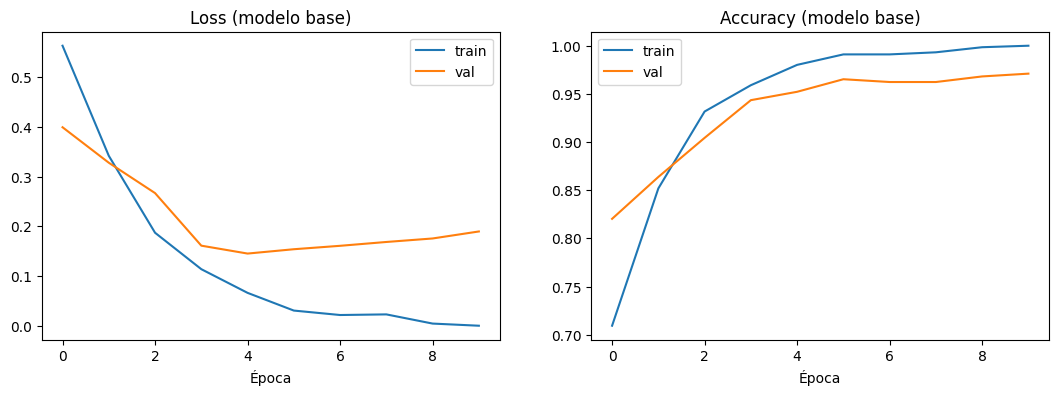

In [18]:
# Curva de entrenamiento
def graficar_historia(hist, titulo=""):
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="val")
    axes[0].set_title(f"Loss {titulo}"); axes[0].set_xlabel("Época"); axes[0].legend()
    axes[1].plot(h["accuracy"], label="train"); axes[1].plot(h["val_accuracy"], label="val")
    axes[1].set_title(f"Accuracy {titulo}"); axes[1].set_xlabel("Época"); axes[1].legend()
    plt.show()

graficar_historia(hist_base, "(modelo base)")

--- modelo base (validación) ---
              precision    recall  f1-score   support

      normal      0.940     0.955     0.948       313
       tumor      0.962     0.950     0.956       377

    accuracy                          0.952       690
   macro avg      0.951     0.952     0.952       690
weighted avg      0.952     0.952     0.952       690



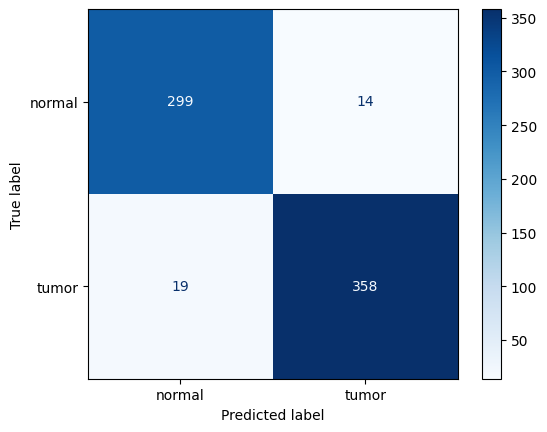

In [19]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def evaluar(model, X, y, nombre="validación"):
    probs = model.predict(X, batch_size=BATCH_SIZE, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    print(f"--- {nombre} ---")
    print(classification_report(y, preds, target_names=["normal", "tumor"], digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y, preds),
                           display_labels=["normal", "tumor"]).plot(cmap="Blues")
    plt.show()
    return probs

probs_val_base = evaluar(modelo_base, X_val, y_val, "modelo base (validación)")

### Evaluación del modelo base

El entrenamiento se detuvo en la época 10 y se restauraron los pesos de la **época 5**, que obtuvo la menor pérdida de validación (0.145).

**Curvas de aprendizaje:** el modelo muestra un **sobreajuste** claro. Desde la época 5, la pérdida de entrenamiento siguió bajando hasta prácticamente cero (≈ 4×10⁻⁴, con 100% de exactitud en la época 10), mientras que la pérdida de validación **empezó a subir** (de 0.145 a 0.190). El modelo memoriza las imágenes de entrenamiento con total confianza, pero esa confianza no se traslada a imágenes nuevas.

**Resultados en validación (pesos de la época 5):**

| Métrica | Normal | Tumor |
|---|---|---|
| Precision | 0.940 | 0.962 |
| Recall | 0.955 | 0.950 |
| F1-score | 0.948 | 0.956 |

Accuracy global: 0.952

**Matriz de confusión:** de 690 imágenes, el modelo cometió 33 errores: **19 falsos negativos** (tumores clasificados como sanos) y 14 falsos positivos (sanos clasificados como tumor). Los falsos negativos son los más graves en un contexto clínico, ya que un paciente con tumor podría no recibir diagnóstico ni tratamiento a tiempo. Por ello, uno de los objetivos del ajuste es aumentar el *recall* de la clase tumor (actualmente 0.950).

**Conclusión del modelo base:** el modelo alcanza un 95.2% de exactitud en validación, una línea base sólida. Sin embargo, la pérdida de validación creciente muestra que memoriza los datos de entrenamiento. Además, el 93% de sus parámetros (3.21 de 3.45 millones) están en la capa densa posterior al `Flatten`, lo que favorece este comportamiento.

## Ajuste del modelo (primera iteración)


Como la base ya es buena, el objetivo no es solo subir el accuracy, sino reducir el sobreajuste y los falsos negativos. Cada cambio ataca un problema que ya identificamos:

| Cambio | Problema que ataca |
|---|---|
| **Data augmentation** | Memorización: el modelo ve variaciones distintas en cada época |
| **GlobalAveragePooling2D** en vez de `Flatten` | Los 3.2M de parámetros en la capa densa: baja la complejidad a unos 0.3M de parámetros en total |
| **BatchNormalization** | Entrenamiento más estable; además regulariza un poco |
| **Dropout(0.4)** | Co-adaptación y dependencia de neuronas específicas |
| **ReduceLROnPlateau** | Ajuste fino de la tasa de aprendizaje cuando el `val_loss` se estanca |

In [20]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

def bloque_conv(x, filtros):
    x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)

def crear_modelo_mejorado():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1./255)(x)
    for f in [32, 64, 128, 256]:
        x = bloque_conv(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inputs, outputs, name="cnn_mejorada")

modelo_v2 = crear_modelo_mejorado()
modelo_v2.summary()

Model: "cnn_mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 406,369 (1.55 MB)

 Trainable params: 405,409 (1.55 MB)

 Non-trainable params: 960 (3.75 KB)

In [21]:
modelo_v2.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc")],
)

callbacks_v2 = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]

hist_v2 = modelo_v2.fit(
    train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks_v2
)

Epoch 1/50
101/101 ━━━━━━━━━━━━━━━━━━━━ 27s 149ms/step - accuracy: 0.6475 - auc: 0.6800 - loss: 0.6603 - precision: 0.6661 - recall: 0.7112 - val_accuracy: 0.5464 - val_auc: 0.5628 - val_loss: 1.1842 - val_precision: 0.5464 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/50
101/101 ━━━━━━━━━━━━━━━━━━━━ 13s 127ms/step - accuracy: 0.6991 - auc: 0.7634 - loss: 0.5821 - precision: 0.7137 - recall: 0.7499 - val_accuracy: 0.5696 - val_auc: 0.5817 - val_loss: 1.2069 - val_precision: 0.6818 - val_recall: 0.3979 - learning_rate: 0.0010
Epoch 3/50
101/101 ━━━━━━━━━━━━━━━━━━━━ 13s 128ms/step - accuracy: 0.7394 - auc: 0.8128 - loss: 0.5267 - precision: 0.7470 - recall: 0.7908 - val_accuracy: 0.5725 - val_auc: 0.6893 - val_loss: 1.3572 - val_precision: 0.9659 - val_recall: 0.2255 - learning_rate: 0.0010
Epoch 4/50
101/101 ━━━━━━━━━━━━━━━━━━━━ 13s 130ms/step - accuracy: 0.7559 - auc: 0.8365 - loss: 0.4944 - precision: 0.7686 - recall: 0.7914 - val_accuracy: 0.6130 - val_auc: 0.8143 - val_loss: 

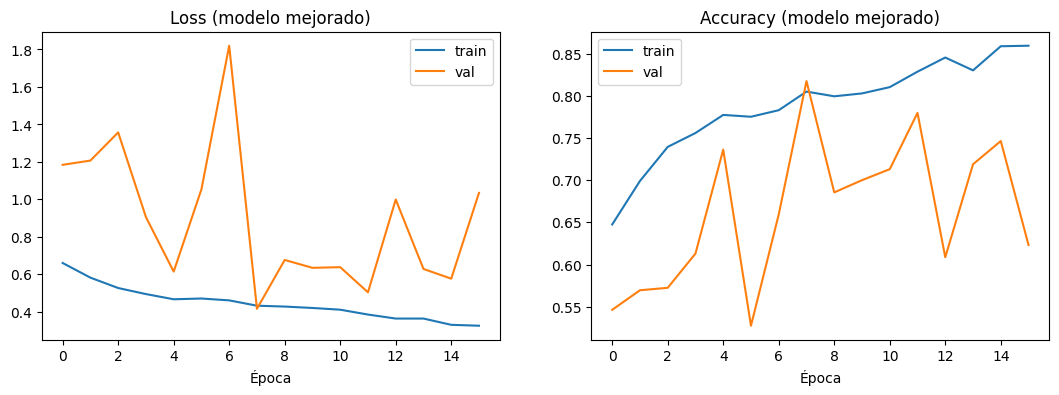

--- modelo mejorado (validación) ---
              precision    recall  f1-score   support

      normal      0.891     0.681     0.772       313
       tumor      0.778     0.931     0.848       377

    accuracy                          0.817       690
   macro avg      0.835     0.806     0.810       690
weighted avg      0.830     0.817     0.813       690



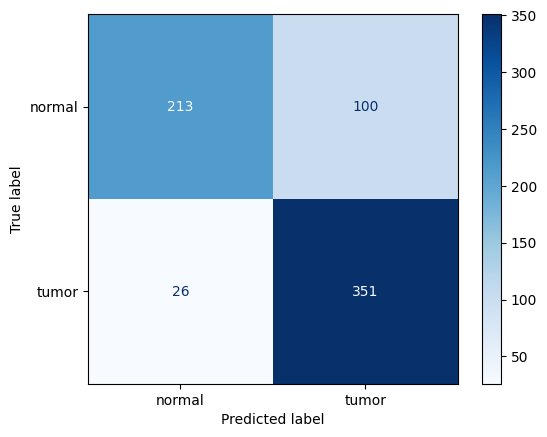

In [22]:
graficar_historia(hist_v2, "(modelo mejorado)")
probs_val_v2 = evaluar(modelo_v2, X_val, y_val, "modelo mejorado (validación)")

In [23]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

def resumen(nombre, probs, y):
    p = (probs >= 0.5).astype(int)
    return {"modelo": nombre,
            "accuracy": accuracy_score(y, p),
            "recall_tumor": recall_score(y, p),
            "f1": f1_score(y, p),
            "auc": roc_auc_score(y, probs),
            "falsos_neg": int(((p == 0) & (y == 1)).sum())}

comparacion = pd.DataFrame([
    resumen("Base", probs_val_base, y_val),
    resumen("Mejorado v2", probs_val_v2, y_val),
]).round(4)
display(comparacion)

,modelo,accuracy,recall_tumor,f1,auc,falsos_neg
0,Base,0.9522,0.9496,0.9559,0.9894,19
1,Mejorado v2,0.8174,0.9310,0.8478,0.9093,26


### Resultados de la iteración 1 en validación

| Modelo | Accuracy | Recall tumor | F1 | AUC | Falsos negativos | Falsos positivos |
|---|---|---|---|---|---|---|
| Base | 0.9522 | 0.9496 | 0.9559 | 0.9894 | 19 | 14 |
| Mejorado v2 | 0.8174 | 0.9310 | 0.8478 | 0.9093 | 26 | 100 |

**Análisis:** los cambios **eliminaron el sobreajuste**: en la mejor época (8), la exactitud de entrenamiento (80.5%) y la de validación (81.7%) quedaron prácticamente iguales. Sin embargo, el desempeño **empeoró en todas las métricas**: la exactitud bajó de 95.2% a 81.7%, el AUC de 0.989 a 0.909, y los falsos negativos subieron de 19 a 26. El modelo pasó de sobreajustado a **subajustado**: la combinación de varias técnicas de regularización resultó demasiado restrictiva para una red pequeña entrenada desde cero con ~3,200 imágenes.

Además, la exactitud de validación **oscila fuertemente** entre épocas (entre 53% y 82%) y el Early Stopping detuvo el entrenamiento en la época 16. Esto se atribuye a la interacción entre `BatchNormalization` y el *augmentation*: las estadísticas que la red calcula durante el entrenamiento (con imágenes alteradas y lotes pequeños) no coinciden con las que usa al evaluar imágenes sin alterar.

La matriz de confusión muestra además 100 falsos positivos: el modelo clasifica como tumor casi una de cada tres imágenes normales.

**Conclusión:** la regularización sí resolvió el problema que buscaba atacar (el sobreajuste), pero entrenar una CNN desde cero no es suficiente para aprender rasgos robustos con este volumen de datos. En la siguiente iteración se utiliza *transfer learning*.

## Transfer learning con EfficientNetB0 (segunda iteración)


Ante el subajuste de la iteración 1, se cambió la estrategia: en lugar de entrenar una CNN desde cero, se reutilizó **EfficientNetB0 preentrenada en ImageNet** (1.2 millones de imágenes). Sus capas convolucionales ya saben detectar bordes, texturas y formas, por lo que solo es necesario adaptarlas a las resonancias magnéticas.

**Arquitectura:** *data augmentation* suave (volteo horizontal, rotación ±0.03 y zoom ±5%, sin cambios de contraste) → EfficientNetB0 sin su clasificador original → `GlobalAveragePooling2D` → `Dropout(0.3)` → `Dense(1, sigmoid)`. EfficientNet incluye su propia normalización de entrada, por lo que se eliminó la capa `Rescaling`.

El entrenamiento se realizó en dos fases:

1. **Base congelada (15 épocas, LR = 1×10⁻³):** solo se entrenó el clasificador nuevo. La exactitud de validación alcanzó 95.5%. En esta fase la validación supera al entrenamiento porque el *Dropout* y el *augmentation* solo actúan durante el entrenamiento.
2. ***Fine-tuning* (20 épocas, LR = 1×10⁻⁵):** se descongelaron las últimas 40 capas de EfficientNet con una tasa de aprendizaje 100 veces menor, para ajustar sus filtros sin destruir lo aprendido. Las capas de `BatchNormalization` se mantuvieron congeladas, ya que actualizar sus estadísticas con pocas imágenes desestabiliza el modelo (problema observado en la iteración 1). La exactitud de validación subió a 96.7% (pesos de la época 15), con curvas estables y una diferencia mínima entre entrenamiento y validación.

In [24]:
from tensorflow.keras.applications import EfficientNetB0

# Augmentation más suave que en v2 (sin RandomContrast)
aug_suave = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
], name="aug_suave")

base_eff = EfficientNetB0(include_top=False, weights="imagenet",
                          input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_eff.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = aug_suave(inputs)
# EfficientNet incluye su propia normalización: recibe píxeles 0-255, sin Rescaling
x = base_eff(x, training=False)   # BatchNorm de la base siempre en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
modelo_tl = models.Model(inputs, outputs, name="efficientnetb0_tl")

modelo_tl.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_suave (Sequential)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 24s 145ms/step - accuracy: 0.7742 - auc: 0.8514 - loss: 0.4934 - precision: 0.7807 - recall: 0.8158 - val_accuracy: 0.9000 - val_auc: 0.9562 - val_loss: 0.3393 - val_precision: 0.8889 - val_recall: 0.9337
Epoch 2/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 9s 89ms/step - accuracy: 0.8571 - auc: 0.9300 - loss: 0.3565 - precision: 0.8659 - recall: 0.8738 - val_accuracy: 0.9203 - val_auc: 0.9715 - val_loss: 0.2746 - val_precision: 0.9149 - val_recall: 0.9416
Epoch 3/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - accuracy: 0.8807 - auc: 0.9475 - loss: 0.3095 - precision: 0.8805 - recall: 0.9045 - val_accuracy: 0.9348 - val_auc: 0.9788 - val_loss: 0.2441 - val_precision: 0.9213 - val_recall: 0.9629
Epoch 4/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.8950 - auc: 0.9603 - loss: 0.2761 - precision: 0.8963 - recall: 0.9136 - val_accuracy: 0.9391 - val_auc: 0.9824 - val_loss: 0.2184 - val_precision: 0.9351 - val_recall: 0.9549
Epoch 5/15
101/101 ━━━━━━━

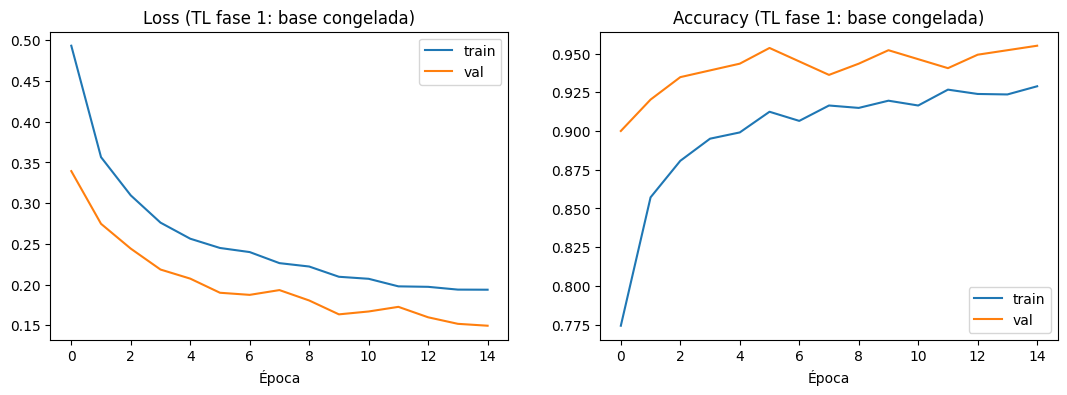

In [25]:
metricas = ["accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")]

modelo_tl.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy", metrics=metricas)

hist_tl1 = modelo_tl.fit(
    train_ds, validation_data=val_ds, epochs=15,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                             restore_best_weights=True)]
)
graficar_historia(hist_tl1, "(TL fase 1: base congelada)")

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 24s 125ms/step - accuracy: 0.9326 - auc: 0.9835 - loss: 0.1792 - precision: 0.9378 - recall: 0.9466 - val_accuracy: 0.9551 - val_auc: 0.9921 - val_loss: 0.1339 - val_precision: 0.9391 - val_recall: 0.9814 - learning_rate: 1.0000e-05
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - accuracy: 0.9366 - auc: 0.9845 - loss: 0.1622 - precision: 0.9440 - recall: 0.9397 - val_accuracy: 0.9435 - val_auc: 0.9934 - val_loss: 0.1493 - val_precision: 0.9163 - val_recall: 0.9867 - learning_rate: 1.0000e-05
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.9466 - auc: 0.9872 - loss: 0.1479 - precision: 0.9521 - recall: 0.9500 - val_accuracy: 0.9565 - val_auc: 0.9940 - val_loss: 0.1269 - val_precision: 0.9392 - val_recall: 0.9841 - learning_rate: 1.0000e-05
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.9466 - auc: 0.9874 - loss: 0.1452 - precision: 0.9501 - recall: 0.9522 - val_accuracy: 0.9580 - val_auc: 0.9948 -

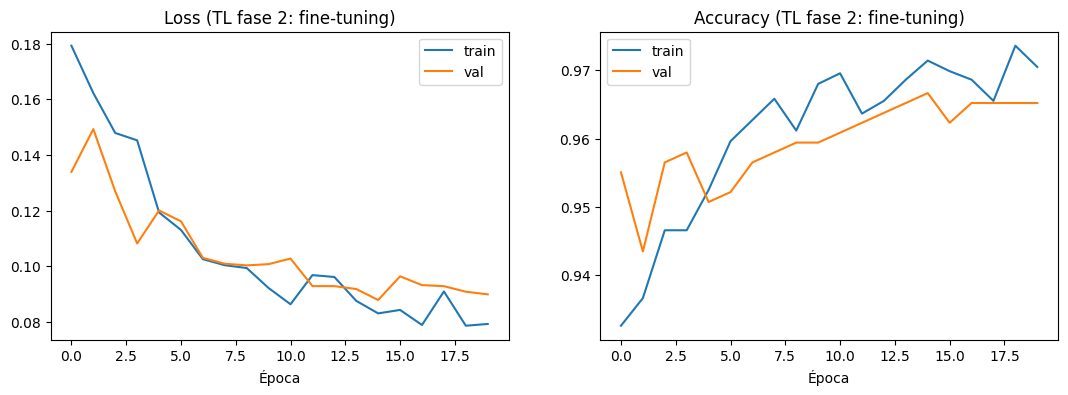

In [26]:
base_eff.trainable = True
for capa in base_eff.layers[:-40]:
    capa.trainable = False
for capa in base_eff.layers:                 # BatchNorm se mantiene congelada
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False

modelo_tl.compile(optimizer=keras.optimizers.Adam(1e-5),   # LR 100 veces menor
                  loss="binary_crossentropy", metrics=metricas)

hist_tl2 = modelo_tl.fit(
    train_ds, validation_data=val_ds, epochs=20,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
    ]
)
graficar_historia(hist_tl2, "(TL fase 2: fine-tuning)")
modelo_tl.save("modelo_tl.keras")

--- transfer learning (validación) ---
              precision    recall  f1-score   support

      normal      0.980     0.946     0.963       313
       tumor      0.956     0.984     0.970       377

    accuracy                          0.967       690
   macro avg      0.968     0.965     0.966       690
weighted avg      0.967     0.967     0.967       690



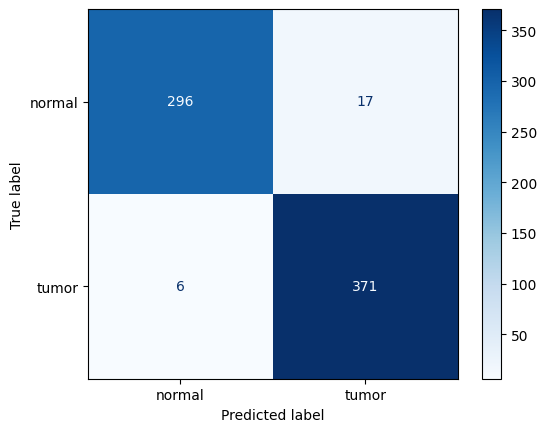

,modelo,accuracy,recall_tumor,f1,auc,falsos_neg
0,Base,0.9522,0.9496,0.9559,0.9894,19
1,Mejorado v2,0.8174,0.9310,0.8478,0.9093,26
2,EfficientNetB0 TL,0.9667,0.9841,0.9699,0.9970,6


In [27]:
probs_val_tl = evaluar(modelo_tl, X_val, y_val, "transfer learning (validación)")

comparacion = pd.DataFrame([
    resumen("Base", probs_val_base, y_val),
    resumen("Mejorado v2", probs_val_v2, y_val),
    resumen("EfficientNetB0 TL", probs_val_tl, y_val),
]).round(4)
display(comparacion)

### Comparación de los tres modelos en validación

| Modelo | Accuracy | Recall tumor | F1 | AUC | Falsos negativos |
|---|---|---|---|---|---|
| Base (CNN desde cero) | 0.9522 | 0.9496 | 0.9559 | 0.9894 | 19 |
| v2 (CNN regularizada) | 0.8174 | 0.9310 | 0.8478 | 0.9093 | 26 |
| **EfficientNetB0 TL** | **0.9667** | **0.9841** | **0.9699** | **0.9970** | **6** |

### ¿Qué cambios funcionaron y por qué?

- **Transfer learning (funcionó):** fue el cambio con mayor impacto. Con ~3,200 imágenes, una red desde cero no alcanza a aprender rasgos visuales robustos; una red preentrenada ya los tiene y solo los adapta. Frente al modelo base, redujo los falsos negativos de 19 a 6, llevó el *recall* de tumor de 0.950 a 0.984 y el AUC de 0.989 a 0.997.
- ***Fine-tuning* con LR baja y BatchNorm congelada (funcionó):** subió la exactitud de validación de 95.5% (base congelada) a 96.7% y bajó la pérdida de validación de 0.149 a 0.088, con curvas estables.
- ***Augmentation* suave (funcionó):** a diferencia de la iteración 1, transformaciones pequeñas y anatómicamente realistas regularizaron sin dificultar el aprendizaje.
- **Regularización agresiva en una red pequeña (no funcionó):** eliminó el sobreajuste, pero provocó subajuste, oscilaciones en validación y más falsos negativos.

Por estos resultados, se eligió **EfficientNetB0 con fine-tuning** como modelo final.

## Resultados

--- MODELO FINAL (prueba) ---
              precision    recall  f1-score   support

      normal      0.983     0.901     0.940       313
       tumor      0.923     0.987     0.954       377

    accuracy                          0.948       690
   macro avg      0.953     0.944     0.947       690
weighted avg      0.950     0.948     0.948       690



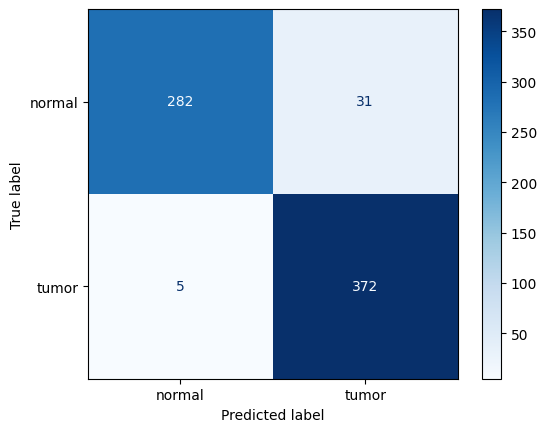

,modelo,accuracy,recall_tumor,f1,auc,falsos_neg
0,EfficientNetB0 TL (test),0.9478,0.9867,0.9538,0.9961,5


In [28]:
modelo_final = modelo_tl
probs_test = evaluar(modelo_final, X_test, y_test, "MODELO FINAL (prueba)")

res_test = resumen("EfficientNetB0 TL (test)", probs_test, y_test)
display(pd.DataFrame([res_test]).round(4))

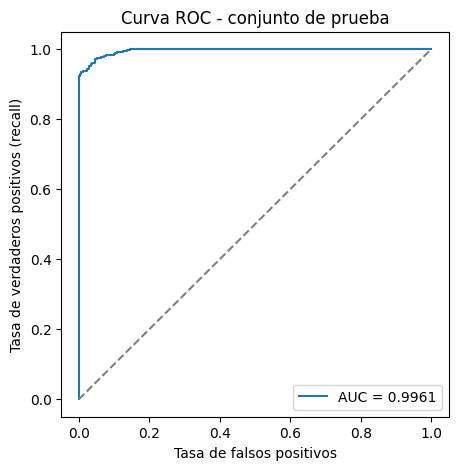

In [29]:
# Curva ROC
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, probs_test)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, probs_test):.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curva ROC - conjunto de prueba"); plt.legend()
plt.show()

Errores en prueba: 36


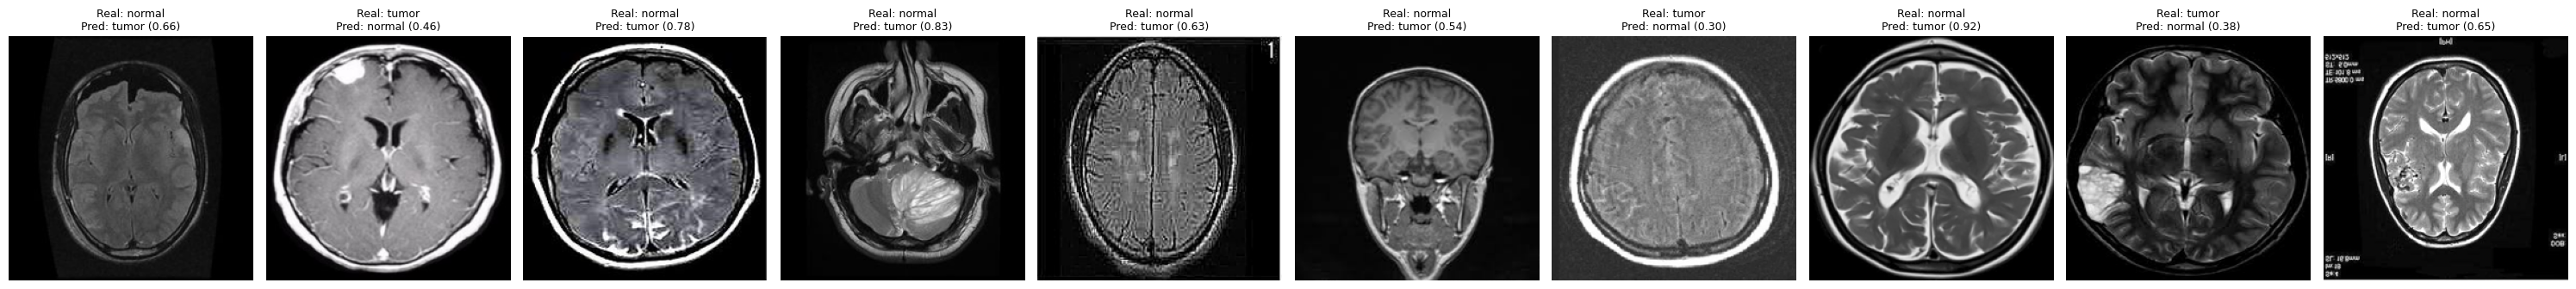

In [30]:
# Imagenes mal clasificadas
preds_test = (probs_test >= 0.5).astype(int)
errores = np.where(preds_test != y_test)[0]
print("Errores en prueba:", len(errores))

nombres = ["normal", "tumor"]
n = min(len(errores), 10)
if n > 0:
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5), squeeze=False)
    for ax, i in zip(axes[0], errores[:n]):
        ax.imshow(X_test[i])
        ax.set_title(f"Real: {nombres[int(y_test[i])]}\nPred: {nombres[preds_test[i]]} ({probs_test[i]:.2f})",
                     fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Análisis de resultados en prueba

El modelo final (EfficientNetB0 con *fine-tuning*) se evaluó una única vez con el conjunto de prueba (690 imágenes no utilizadas durante el entrenamiento ni el ajuste):

| Métrica | Normal | Tumor |
|---|---|---|
| Precision | 0.983 | 0.923 |
| Recall | 0.901 | 0.987 |
| F1-score | 0.940 | 0.954 |

**Accuracy:** 0.948 · **AUC:** 0.996 · **Falsos negativos:** 5 de 377 tumores · **Falsos positivos:** 31 de 313 imágenes normales

**Análisis:**

- **Detección de tumores:** el modelo identificó correctamente el 98.7% de los tumores. Este es el resultado más relevante desde el punto de vista clínico, ya que los falsos negativos son el error más grave.
- **Diferencia con validación:** la exactitud bajó de 96.7% a 94.8%, principalmente por un aumento de falsos positivos (de 17 a 31), mientras que los falsos negativos se mantuvieron prácticamente iguales (6 en validación y 5 en prueba). Es decir, el modelo tiende a clasificar como tumor los casos dudosos.
- **Curva ROC:** el AUC de 0.996 indica que el modelo separa casi perfectamente ambas clases. Muchos errores están cerca del umbral de decisión de 0.5: entre los 10 errores mostrados, los falsos negativos tienen probabilidades de tumor entre 0.30 y 0.46, y 4 de los 7 falsos positivos están entre 0.54 y 0.66. Esto indica que el desempeño podría mejorar ajustando el umbral.
- **Análisis de errores:** las imágenes mal clasificadas incluyen cortes no axiales (coronales o a la altura del cerebelo), imágenes con texto y anotaciones del equipo de resonancia, y secuencias FLAIR con zonas hiperintensas que el modelo confunde con lesiones. Además, algunas imágenes etiquetadas como normales parecen presentar alteraciones visibles, lo que sugiere posible ruido en las etiquetas del dataset.


In [31]:
modelo_final.save("modelo_brain_tumor.keras")

modelo_cargado = keras.models.load_model("modelo_brain_tumor.keras")
probs_check = modelo_cargado.predict(X_test[:5], verbose=0).ravel()
print("Predicciones del modelo recargado:", probs_check.round(4))
print("Coinciden con el original:", np.allclose(probs_check, probs_test[:5], atol=1e-5))

Predicciones del modelo recargado: [0.0729 0.9993 1.     0.0276 0.9982]
Coinciden con el original: True


## Aplicación

La función `predecir_tumor` recibe la ruta de una imagen de resonancia magnética en cualquier formato (JPEG, PNG o TIFF; RGB o escala de grises), la preprocesa igual que en el entrenamiento y devuelve la clase predicha con su probabilidad.

In [32]:
modelo_app = keras.models.load_model("modelo_brain_tumor.keras")

def predecir_tumor(ruta_imagen, modelo=modelo_app, umbral=0.5, mostrar=True):
    img = Image.open(ruta_imagen).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    x = np.expand_dims(np.asarray(img, dtype=np.float32), axis=0)

    prob_tumor = float(modelo.predict(x, verbose=0)[0, 0])
    clase = "Tumor" if prob_tumor >= umbral else "Normal"
    confianza = prob_tumor if clase == "Tumor" else 1 - prob_tumor

    if mostrar:
        plt.imshow(img)
        plt.title(f"{clase} (confianza: {confianza:.1%})")
        plt.axis("off")
        plt.show()

    return {"clase": clase, "prob_tumor": round(prob_tumor, 4), "confianza": round(confianza, 4)}

### Predicciones con imágenes nuevas

Para evaluar la capacidad de generalización del modelo, se probaron tres imágenes obtenidas de fuentes externas al dataset, que el modelo no vio en ningún momento:

| Archivo | Clase real | Fuente |
|---|---|---|
| `test1.jpg` | Tumor | [Elsevier – Medicina Integral](https://www.elsevier.es/es-revista-medicina-integral-63-articulo-resonancia-magnetica-nuclear-cerebral-10022166) |
| `test2.jpg` | Tumor | [Elsevier – Medicina Integral](https://www.elsevier.es/es-revista-medicina-integral-63-articulo-resonancia-magnetica-nuclear-cerebral-10022166) |
| `test3.jpg` | Normal | [Sapiens UMH – Arquitectura del cerebro](https://sapiens.umh.es/arquitectura-del-cerebro/) |

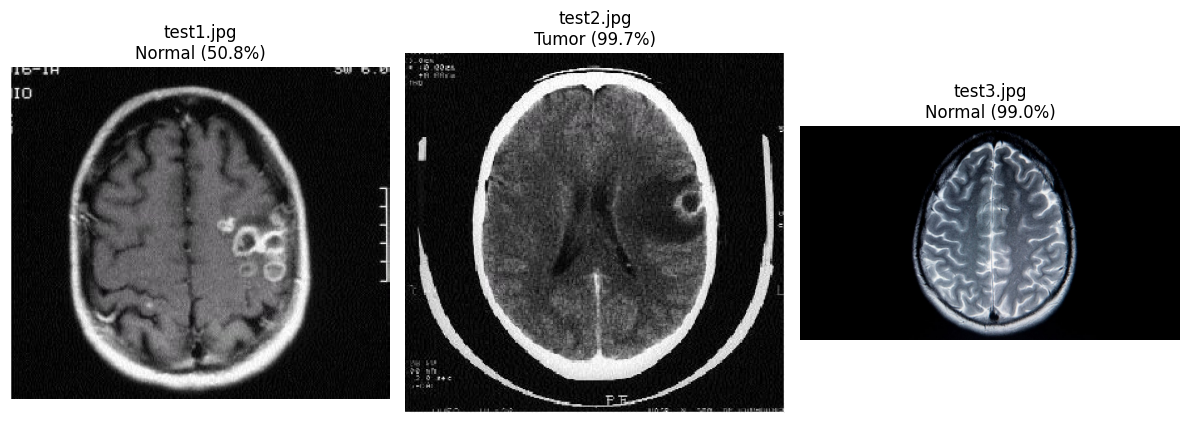

In [42]:
archivos = sorted(f for f in os.listdir(CARPETA_NUEVAS)
                  if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")))

fig, axes = plt.subplots(1, len(archivos), figsize=(4 * len(archivos), 4.5), squeeze=False)
for ax, archivo in zip(axes[0], archivos):
    ruta = os.path.join(CARPETA_NUEVAS, archivo)
    r = predecir_tumor(ruta, mostrar=False)
    ax.imshow(Image.open(ruta).convert("RGB"))
    ax.set_title(f"{archivo}\n{r['clase']} ({r['confianza']:.1%})")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [43]:
for archivo in archivos:
    ruta = os.path.join(CARPETA_NUEVAS, archivo)
    print(f"{archivo:10s} ->", predecir_tumor(ruta, mostrar=False))

test1.jpg  -> {'clase': 'Normal', 'prob_tumor': 0.4917, 'confianza': 0.5083}
test2.jpg  -> {'clase': 'Tumor', 'prob_tumor': 0.997, 'confianza': 0.997}
test3.jpg  -> {'clase': 'Normal', 'prob_tumor': 0.0098, 'confianza': 0.9902}


**Resultados con imágenes externas:**

| Archivo | Clase real | Predicción | Probabilidad de tumor | ¿Correcta? |
|---|---|---|---|---|
| `test1.jpg` | Tumor | Normal | 0.492 | No |
| `test2.jpg` | Tumor | Tumor | 0.997 | Sí |
| `test3.jpg` | Normal | Normal | 0.010 | Sí  |

El modelo acertó 2 de 3 imágenes. El error (`test1.jpg`) quedó prácticamente en el umbral (0.492 frente a 0.5) y se trata de una imagen con texto y marcas del equipo en los bordes, distintas a las del dataset. `test2.jpg` parece corresponder a una tomografía computarizada (TC) más que a una resonancia, por lo que su acierto no garantiza que el modelo funcione en general con esa modalidad. `test3.jpg` es rectangular, por lo que se deforma al redimensionarla a 224×224, y aun así se clasificó correctamente.

## Conclusiones

Se desarrolló un clasificador de resonancias magnéticas cerebrales capaz de distinguir entre imágenes con tumor y sin tumor, con una exactitud de 94.8% y un *recall* de 98.7% para la clase tumor en el conjunto de prueba.

**Sobre el proceso de desarrollo:**

- La CNN entrenada desde cero alcanzó un buen desempeño inicial (95.2% en validación), pero memorizó los datos de entrenamiento.
- Aplicar regularización agresiva sobre esa misma red eliminó el sobreajuste, pero provocó subajuste y empeoró los resultados (81.7% en validación). Esto mostró que la regularización debe ser proporcional a la capacidad del modelo y al volumen de datos.
- El cambio más efectivo fue el *transfer learning* con EfficientNetB0: con solo ~3,200 imágenes de entrenamiento, reutilizar rasgos aprendidos en ImageNet produjo un modelo más preciso, más estable y con muchos menos falsos negativos (de 19 a 6 en validación).

**Sobre las predicciones con imágenes externas:** el modelo clasificó correctamente 2 de 3 imágenes obtenidas de otras fuentes. El error fue una imagen con tumor clasificada como normal con una probabilidad de tumor de 0.49, prácticamente en el umbral, y con anotaciones del equipo en los bordes. Esto muestra que el modelo es sensible a diferencias en el formato y la procedencia de las imágenes.

**Limitaciones:**

- El dataset es una recopilación de varias fuentes, con imágenes de distintos tamaños, secuencias de resonancia y cortes, y posible ruido en las etiquetas. Además, el dataset incluye archivos con el mismo nombre en distintos formatos (por ejemplo, `Cancer (1).jpg`, `Cancer (1).png` y `Cancer (1).tif`), por lo que podrían existir imágenes repetidas o casi duplicadas entre entrenamiento y prueba, lo que inflaría las métricas.
- Todos los archivos TIFF pertenecen a la clase tumor. Aunque todas las imágenes se convirtieron al mismo formato, no se puede descartar que el modelo aproveche diferencias de origen (resolución, compresión, estilo de la fuente) en lugar de rasgos del tumor.
- El modelo solo distingue entre tumor y no tumor; no identifica el tipo de tumor ni su ubicación.
- No ha sido validado clínicamente, por lo que solo podría usarse como herramienta de apoyo y nunca como sustituto del diagnóstico de un especialista.

**Áreas de mejora:**

- **Ajustar el umbral de decisión** con el conjunto de validación, buscando el punto que mantenga un *recall* alto de tumores con menos falsos positivos.
- **Filtrar o estandarizar las imágenes:** recortar el cerebro, eliminar texto y anotaciones, y separar cortes axiales de coronales y sagitales.
- **Detectar y eliminar imágenes duplicadas** antes de dividir el dataset.
- **Probar otras arquitecturas preentrenadas** (EfficientNetB3, ResNet50, DenseNet121) o ensambles de modelos.
- **Agregar interpretabilidad** con Grad-CAM, para visualizar qué regiones de la imagen utiliza el modelo y verificar que se basa en la lesión y no en artefactos.
- **Ampliar a clasificación multiclase** (glioma, meningioma, tumor pituitario, sin tumor) con un dataset etiquetado por tipo.
- **Agrupar las imágenes por origen** (mismo número de archivo en distintos formatos) al hacer la división, para evitar que una misma imagen quede en entrenamiento y en prueba.